# Step 34: Expert versus novice (review E12, role part)
Engagement and model accuracy by role and language (XGBoost on the 797 voice + face features, 6 speaker-independent folds), and a role-only baseline that predicts the training mean of the person's role with no features. Partner features were not analysed.
*This notebook only loads the saved results of `src/34_role_analysis.py`; it does not train anything and needs no NoXi data.*

**In short** (what this notebook shows)

- **What:** Expert vs novice (review E12, role part): engagement and accuracy by role and language, and the role-only baseline.
- **Needs the NoXi data?** No: it loads reports/role_*.csv (made by src/34_role_analysis.py).
- **Result / use:** Experts are more engaged in all 24 sessions; knowing only the role already gives CCC 0.434 (XGBoost 0.629).

Go to the project folder.

In [2]:
import os
if os.getcwd().endswith("notebooks"):
    os.chdir("..")          # work from the project folder

**Imports.**

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
pd.set_option('display.width', 220)

In [4]:
ra = pd.read_csv('reports/role_analysis.csv')
print(ra.round(3).to_string(index=False))
print()
print(pd.read_csv('reports/role_stats.csv').round(4).to_string(index=False))

  role language  windows  mean_engagement  std_engagement  model_ccc_fold_mean  model_ccc_session_mean  role_mean_baseline_ccc
expert  English     7537            0.596           0.126                0.425                   0.392                     NaN
expert   French     9530            0.682           0.149                0.446                   0.463                     NaN
expert   German     7176            0.675           0.106                0.387                   0.410                     NaN
expert      all    24243            0.653           0.136                0.459                   0.421                     NaN
novice  English     7537            0.486           0.134                0.379                   0.371                     NaN
novice   French     9530            0.519           0.114                0.608                   0.576                     NaN
novice   German     7176            0.482           0.093                0.649                   0.638         

**Chart.** Mean engagement and model CCC for experts and novices in each language.

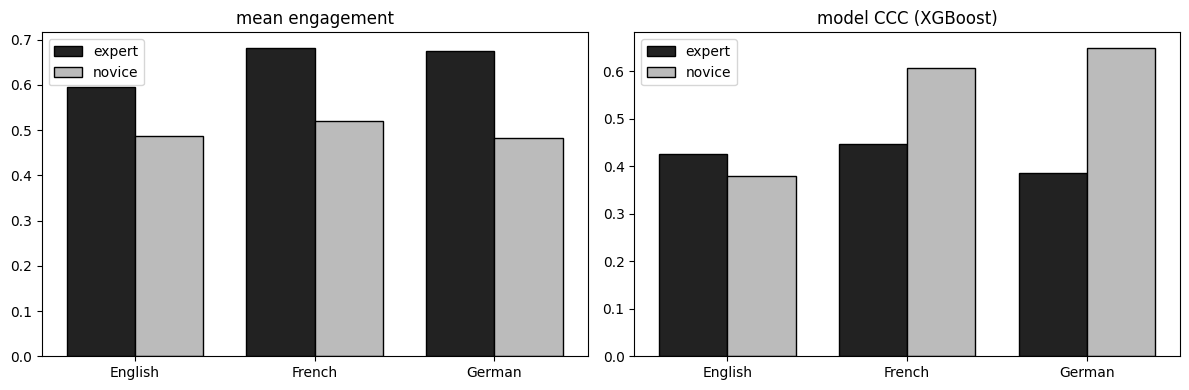

In [5]:
r = ra[(ra.role != 'both') & (ra.language != 'all')]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, t in zip(ax, ['mean_engagement', 'model_ccc_fold_mean'], ['mean engagement', 'model CCC (XGBoost)']):
    for k, role in enumerate(['expert', 'novice']):
        d = r[r.role == role]; a.bar([i + (k - 0.5) * 0.38 for i in range(3)], d[col], 0.38, color=['#222222', '#bbbbbb'][k], edgecolor='black', label=role)
    a.set_xticks(range(3)); a.set_xticklabels(['English', 'French', 'German']); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

**Reading.** Experts are more engaged than novices in all 24 sessions (0.653 against 0.498). The role alone, with no features, already gives CCC 0.434 against 0.629 for XGBoost, so part of the pooled score reflects the difference between the roles; the features still add a lot. The model is more accurate for novices (0.570) than for experts (0.459; per-session difference -0.107, p = 0.021).